# Exploratory Data Analysis (EDA) - Customer Return Propensity
## Dataset 1: E-Commerce Orders & Customer Attributes
---
### Project Objective:
This notebook performs a comprehensive, modular Exploratory Data Analysis (EDA) on the E-Commerce Orders dataset to determine:
1. Data quality, integrity, and cleanliness.
2. Distribution of customer attributes, order features, and logistics signals.
3. Class balance and patterns in the target variable (`Returned`).
4. **Machine Learning Suitability Verdict**: Whether this dataset provides sufficient predictive signal to build an ML model predicting customer product returns.


### 1.1 Importing Required Libraries and Configuring Visual Aesthetics
Import data manipulation, statistical analysis, and plotting libraries. Configure clean styling parameters for all matplotlib and seaborn visualizations.


In [1]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')

# Set aesthetic configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Libraries imported successfully!")


Libraries imported successfully!


### 1.2 Configuring File Paths and Loading Data Dictionary & Primary Dataset
Establish dynamic file paths with robust fallbacks to load `data_dictionary.csv` and `ecommerce_orders_dataset.csv`.


In [2]:
# Define dataset paths with relative discovery and absolute fallbacks
current_dir = os.getcwd()
relative_data_dir = os.path.abspath(os.path.join(current_dir, "..", "..", "dataset", "Dataset 1"))

dict_candidate = os.path.join(relative_data_dir, "data_dictionary.csv")
dataset_candidate = os.path.join(relative_data_dir, "ecommerce_orders_dataset.csv")

# Fallback to absolute paths if running from an unconventional root
dict_path = dict_candidate if os.path.exists(dict_candidate) else r"C:\Users\Acer\Desktop\E_Commerce_Return_Prediction\dataset\Dataset 1\data_dictionary.csv"
dataset_path = dataset_candidate if os.path.exists(dataset_candidate) else r"C:\Users\Acer\Desktop\E_Commerce_Return_Prediction\dataset\Dataset 1\ecommerce_orders_dataset.csv"

# Load datasets
data_dict_df = pd.read_csv(dict_path)
df = pd.read_csv(dataset_path)

print(f"Data Dictionary loaded from: {dict_path}")
print(f"Data Dictionary shape: {data_dict_df.shape}")
print(f"Primary Dataset loaded from: {dataset_path}")
print(f"Primary Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")


Data Dictionary loaded from: c:\Users\Acer\Desktop\E_Commerce_Return_Prediction\dataset\Dataset 1\data_dictionary.csv
Data Dictionary shape: (41, 2)
Primary Dataset loaded from: c:\Users\Acer\Desktop\E_Commerce_Return_Prediction\dataset\Dataset 1\ecommerce_orders_dataset.csv
Primary Dataset shape: 30,000 rows x 41 columns


### 1.3 Inspecting Data Dictionary and Feature Descriptions
Display the complete feature dictionary to understand the business definition, scope, and expected format of every column in the dataset.


In [3]:
print("--- DATA DICTIONARY OVERVIEW ---")
data_dict_df.style.set_properties(**{'text-align': 'left'})
display(data_dict_df)


--- DATA DICTIONARY OVERVIEW ---


,Column,Description
0,Order_ID,Unique order identifier
1,Customer_ID,Unique customer identifier
2,Order_Date,Date when the order was placed
3,Year,Order year
4,Month,Order month
5,Day,Order day
6,Day_Of_Week,Day of the week
7,Quarter,Business quarter
8,Customer_Age,Customer age in years
9,Customer_Gender,Customer gender


### 2.1 Examining Dataset Dimensions, Data Types, and Memory Footprint
Audit the total number of records, memory usage, and column data types to identify numerical vs. categorical variables.


In [4]:
print("=== DATASET GENERAL INFO ===")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Features: {df.shape[1]}")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print("\n=== DATA TYPES BREAKDOWN ===")
print(df.dtypes.value_counts())
print("\n=== DETAILED COLUMN INFORMATION ===")
df.info()


=== DATASET GENERAL INFO ===
Total Rows: 30,000
Total Features: 41
Memory Usage: 40.79 MB

=== DATA TYPES BREAKDOWN ===
object     23
int64       9
float64     9
Name: count, dtype: int64

=== DETAILED COLUMN INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 41 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Order_ID                 30000 non-null  int64  
 1   Customer_ID              30000 non-null  object 
 2   Order_Date               30000 non-null  object 
 3   Year                     30000 non-null  int64  
 4   Month                    30000 non-null  int64  
 5   Day                      30000 non-null  int64  
 6   Day_Of_Week              30000 non-null  object 
 7   Quarter                  30000 non-null  int64  
 8   Customer_Age             30000 non-null  int64  
 9   Customer_Gender          30000 non-null  object 
 10  Country      

### 2.2 Previewing Head and Tail Records
Inspect sample observations from the beginning and end of the dataset to verify column alignment, formats, and realistic value ranges.


In [5]:
print("--- FIRST 5 ROWS ---")
display(df.head(5))

print("--- LAST 5 ROWS ---")
display(df.tail(5))


--- FIRST 5 ROWS ---


,Order_ID,Customer_ID,Order_Date,Year,Month,Day,Day_Of_Week,Quarter,Customer_Age,Customer_Gender,Country,City,Customer_Segment,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Quantity,Discount_Percent,Discount_Amount,Coupon_Used,Shipping_Cost,Tax_Amount,Order_Amount,Payment_Method,Device_Type,Traffic_Source,Membership_Status,Shipping_Method,Warehouse_Region,Delivery_Days,Order_Status,Returned,Review_Rating,Customer_Lifetime_Value,Profit_Margin_Percent,Profit_Amount,Season,Holiday_Season,High_Value_Order
0,615717,CUST007322,2023-01-01,2023,1,1,Sunday,1,32,Male,Germany,Dubai,Loyal,PROD02374,Books,Comics,PrimePlus,18.440,3,10,5.530,Yes,15.500,2.910,68.200,Debit Card,Mobile,Social Media,Standard,Express,North,2,Delivered,No,4.400,2144.920,23.100,15.750,Winter,No,No
1,626919,CUST004717,2023-01-01,2023,1,1,Sunday,1,50,Male,France,London,Returning,PROD01378,Sports,Equipment,PrimePlus,46.580,1,40,18.630,Yes,5.870,4.910,38.730,Wallet,Mobile,Email,Standard,Standard,East,9,Delivered,No,4.100,817.170,8.570,3.320,Winter,No,No
2,615781,CUST004415,2023-01-01,2023,1,1,Sunday,1,61,Male,India,Berlin,Returning,PROD01850,Beauty,Skincare,Zenith,62.180,3,35,65.290,Yes,15.910,16.500,153.660,Cash on Delivery,Mobile,Paid Ads,Standard,Express,Central,2,Delivered,No,5.000,541.160,29.720,45.670,Winter,No,No
3,621747,CUST004114,2023-01-01,2023,1,1,Sunday,1,34,Male,United States,Riyadh,Returning,PROD00545,Fashion,Women Clothing,FreshMart,91.060,3,0,0.000,No,9.170,16.020,298.370,Wallet,Desktop,Organic Search,Standard,Standard,South,6,Returned,Yes,3.400,700.490,25.220,75.250,Winter,No,No
4,625881,CUST000145,2023-01-01,2023,1,1,Sunday,1,37,Male,India,Mumbai,Premium,PROD01398,Beauty,Makeup,Zenith,99.440,1,15,14.920,Yes,13.630,7.600,105.750,PayPal,Mobile,Referral,Standard,Express,Central,8,Delivered,No,3.600,2133.770,24.640,26.060,Winter,No,No


--- LAST 5 ROWS ---


,Order_ID,Customer_ID,Order_Date,Year,Month,Day,Day_Of_Week,Quarter,Customer_Age,Customer_Gender,Country,City,Customer_Segment,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Quantity,Discount_Percent,Discount_Amount,Coupon_Used,Shipping_Cost,Tax_Amount,Order_Amount,Payment_Method,Device_Type,Traffic_Source,Membership_Status,Shipping_Method,Warehouse_Region,Delivery_Days,Order_Status,Returned,Review_Rating,Customer_Lifetime_Value,Profit_Margin_Percent,Profit_Amount,Season,Holiday_Season,High_Value_Order
29995,603016,CUST006407,2026-12-31,2026,12,31,Thursday,4,28,Female,United Kingdom,London,Loyal,PROD00943,Home & Kitchen,Cookware,Nova,152.000,2,5,15.200,Yes,3.530,32.840,325.170,Bank Transfer,Mobile,Paid Ads,Standard,Standard,South,7,Delivered,No,4.400,4656.300,36.510,118.720,Winter,Yes,No
29996,615920,CUST003743,2026-12-31,2026,12,31,Thursday,4,49,Female,UAE,New York,Loyal,PROD00796,Sports,Fitness,Apex,66.480,3,15,29.920,Yes,6.720,22.830,199.070,Cash on Delivery,Mobile,Direct,Silver,Standard,Central,7,Delivered,No,4.600,3748.590,15.930,31.710,Winter,No,No
29997,603150,CUST005027,2026-12-31,2026,12,31,Thursday,4,41,Male,Australia,Sydney,Returning,PROD00468,Groceries,Beverages,Zenith,31.110,3,0,0.000,No,3.210,5.410,101.950,Credit Card,Mobile,Referral,Gold,Standard,Central,8,Shipped,No,4.100,1726.840,26.930,27.460,Winter,Yes,No
29998,626020,CUST008716,2026-12-31,2026,12,31,Thursday,4,38,Male,Canada,Paris,Returning,PROD00444,Home & Kitchen,Appliances,Nova,61.980,4,10,24.790,Yes,11.700,27.220,262.050,PayPal,Desktop,Social Media,Standard,Standard,East,3,Delivered,No,3.800,2519.080,11.300,29.610,Winter,Yes,No
29999,609440,CUST009000,2026-12-31,2026,12,31,Thursday,4,18,Male,France,Toronto,Returning,PROD00257,Fashion,Women Clothing,ValueMax,53.650,3,20,32.190,Yes,16.540,13.460,158.760,Debit Card,Mobile,Social Media,Silver,Express,Central,4,Shipped,No,3.400,2238.120,39.600,62.870,Winter,Yes,No


### 2.3 Checking Missing Values and Null Percentages
Audit all columns for null, missing, or NaN values to determine completeness and evaluate whether imputation strategies will be necessary.


In [6]:
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': null_counts,
    'Missing_Percentage (%)': null_pct
}).sort_values(by='Missing_Count', ascending=False)

missing_cols = missing_summary[missing_summary['Missing_Count'] > 0]

if len(missing_cols) == 0:
    print("STATUS: ZERO MISSING VALUES! The dataset is 100% complete across all 41 columns.")
else:
    print(f"STATUS: Detected {len(missing_cols)} columns with missing data:")
    display(missing_cols)


STATUS: ZERO MISSING VALUES! The dataset is 100% complete across all 41 columns.


### 2.4 Checking for Duplicate Records and Primary Key Uniqueness
Verify row-level uniqueness and inspect identifier columns (`Order_ID`, `Customer_ID`) to assess customer repeat-purchase rates.


In [7]:
exact_duplicates = df.duplicated().sum()
unique_orders = df['Order_ID'].nunique()
unique_customers = df['Customer_ID'].nunique()
unique_products = df['Product_ID'].nunique()

print(f"Exact Duplicate Rows across all columns: {exact_duplicates}")
print(f"Total Orders: {len(df):,} | Unique Order IDs: {unique_orders:,}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Average Orders per Customer: {len(df) / unique_customers:.2f}")
print(f"Unique Products: {unique_products:,}")


Exact Duplicate Rows across all columns: 0
Total Orders: 30,000 | Unique Order IDs: 30,000
Unique Customers: 8,683
Average Orders per Customer: 3.46
Unique Products: 2,500


### 3.1 Numerical Features: Central Tendency, Spread, and Distributional Metrics
Compute central tendency (Mean, Median), dispersion (Standard Deviation, IQR, Range), and distribution shape (Skewness, Kurtosis) for all numeric columns.


In [8]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Exclude temporal/ID numeric columns from central tendency metrics if present
analysis_numeric = [col for col in numeric_cols if col not in ['Order_ID', 'Year', 'Month', 'Day', 'Quarter']]

stats_list = []
for col in analysis_numeric:
    series = df[col].dropna()
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    
    stats_list.append({
        'Feature': col,
        'Mean': series.mean(),
        'Median': series.median(),
        'Std Dev': series.std(),
        'Min': series.min(),
        '25%': q25,
        '75%': q75,
        'Max': series.max(),
        'IQR': iqr,
        'Skewness': series.skew(),
        'Kurtosis': series.kurtosis()
    })

stats_df = pd.DataFrame(stats_list)
display(stats_df.round(3))


,Feature,Mean,Median,Std Dev,Min,25%,75%,Max,IQR,Skewness,Kurtosis
0,Customer_Age,36.370,36.000,11.316,18.000,28.000,44.000,75.000,16.000,0.285,-0.389
1,Unit_Price,126.820,60.670,172.675,3.840,29.880,128.572,1940.000,98.692,2.744,9.502
2,Quantity,3.081,3.000,1.450,1.000,2.000,4.000,11.000,2.000,0.710,0.519
3,Discount_Percent,12.619,10.000,11.085,0.000,0.000,20.000,40.000,20.000,0.577,-0.613
4,Discount_Amount,49.433,13.470,114.402,0.000,0.000,44.822,2623.900,44.822,6.225,63.570
5,Shipping_Cost,10.317,9.000,5.891,0.000,6.020,14.220,32.600,8.200,0.661,-0.127
6,Tax_Amount,29.144,12.065,49.562,0.260,5.270,29.443,1043.160,24.173,4.459,31.395
7,Order_Amount,379.001,171.030,585.406,6.670,82.948,388.190,10314.270,305.242,3.894,22.792
8,Delivery_Days,4.437,4.000,2.349,0.000,3.000,6.000,13.000,3.000,0.054,-0.434
9,Review_Rating,4.048,4.100,0.686,1.000,3.600,4.600,5.000,1.000,-0.619,0.101


### 3.2 Categorical Features: Cardinality, Mode, and Frequency Distribution
Analyze categorical attributes to examine uniqueness cardinality, most frequent values (mode), and dominance ratios.


In [9]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
# Exclude high-cardinality IDs from tabular display
cat_features = [col for col in categorical_cols if col not in ['Order_ID', 'Customer_ID', 'Product_ID', 'Order_Date']]

cat_summary = []
for col in cat_features:
    val_counts = df[col].value_counts()
    top_val = val_counts.index[0]
    top_freq = val_counts.iloc[0]
    top_pct = (top_freq / len(df)) * 100
    
    cat_summary.append({
        'Feature': col,
        'Unique Values': df[col].nunique(),
        'Top Mode': top_val,
        'Top Mode Frequency': top_freq,
        'Top Mode Share (%)': top_pct
    })

cat_summary_df = pd.DataFrame(cat_summary).sort_values(by='Unique Values', ascending=False)
display(cat_summary_df)


,Feature,Unique Values,Top Mode,Top Mode Frequency,Top Mode Share (%)
6,Product_Subcategory,32,Men Clothing,1591,5.303
3,City,10,London,3089,10.297
7,Brand,10,Zenith,3099,10.330
2,Country,10,Canada,3099,10.330
5,Product_Category,8,Fashion,6092,20.307
0,Day_Of_Week,7,Monday,4327,14.423
11,Traffic_Source,6,Organic Search,5098,16.993
9,Payment_Method,6,Credit Card,5080,16.933
14,Warehouse_Region,5,West,6060,20.200
15,Order_Status,5,Delivered,19497,64.990


### 4.1 Target Variable (`Returned`) Class Distribution & Imbalance Ratio
Analyze the distribution of the target variable `Returned` to determine positive (returned) vs. negative (kept) class proportions and compute the exact imbalance ratio.


In [10]:
target_col = 'Returned'
target_counts = df[target_col].value_counts()
target_pct = df[target_col].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct
})

imbalance_ratio = target_counts['No'] / target_counts['Yes']

print("=== TARGET VARIABLE DISTRIBUTION ===")
display(target_summary.round(2))
print(f"\nClass Imbalance Ratio (Kept:Returned): {imbalance_ratio:.2f} : 1")
print(f"Positive Class (Returned = 'Yes') Prevalence: {target_pct['Yes']:.2f}%")
print(f"Negative Class (Returned = 'No') Prevalence: {target_pct['No']:.2f}%")


=== TARGET VARIABLE DISTRIBUTION ===


,Count,Percentage (%)
Returned,,
No,26967,89.890
Yes,3033,10.110



Class Imbalance Ratio (Kept:Returned): 8.89 : 1
Positive Class (Returned = 'Yes') Prevalence: 10.11%
Negative Class (Returned = 'No') Prevalence: 89.89%


### 4.2 Target Variable Visualization: Bar Chart & Donut Chart
Generate visual plots showing the frequency count and percentage split of product returns to provide an intuitive baseline for ML modeling.


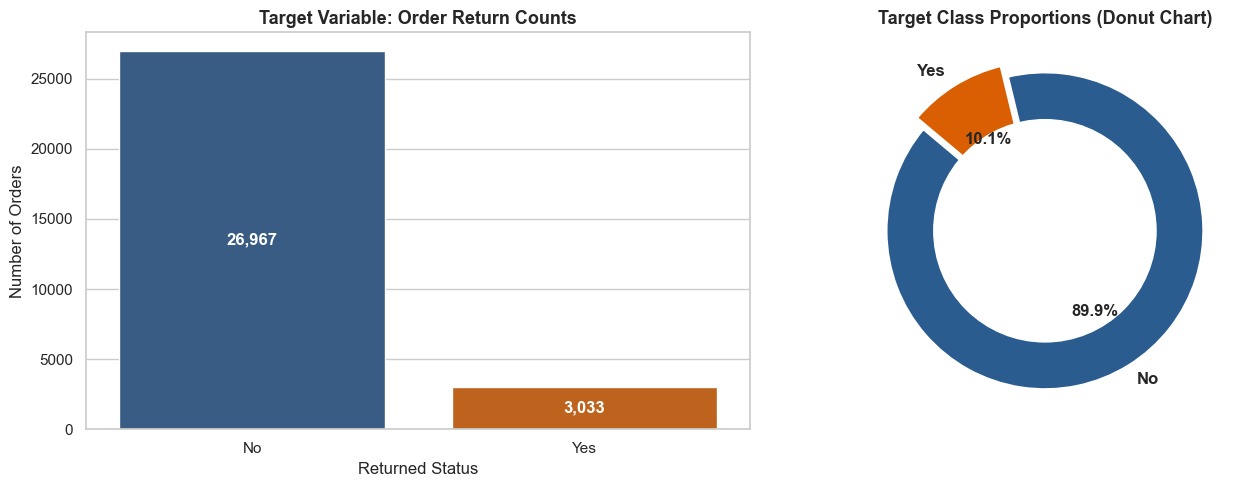

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Countplot
colors = ['#2b5c8f', '#d95f02']
sns.countplot(data=df, x='Returned', palette=colors, ax=axes[0])
axes[0].set_title('Target Variable: Order Return Counts', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Returned Status')
axes[0].set_ylabel('Number of Orders')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Subplot 2: Donut Chart
axes[1].pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', 
            startangle=140, colors=colors, explode=(0, 0.08), 
            textprops={'fontsize': 12, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title('Target Class Proportions (Donut Chart)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 5.1 Numerical Features: Distribution Histograms and Kernel Density Estimates
Plot distribution curves for key numerical attributes (Customer Age, Unit Price, Order Amount, Delivery Days, CLV) to examine skewness, multi-modality, and spread.


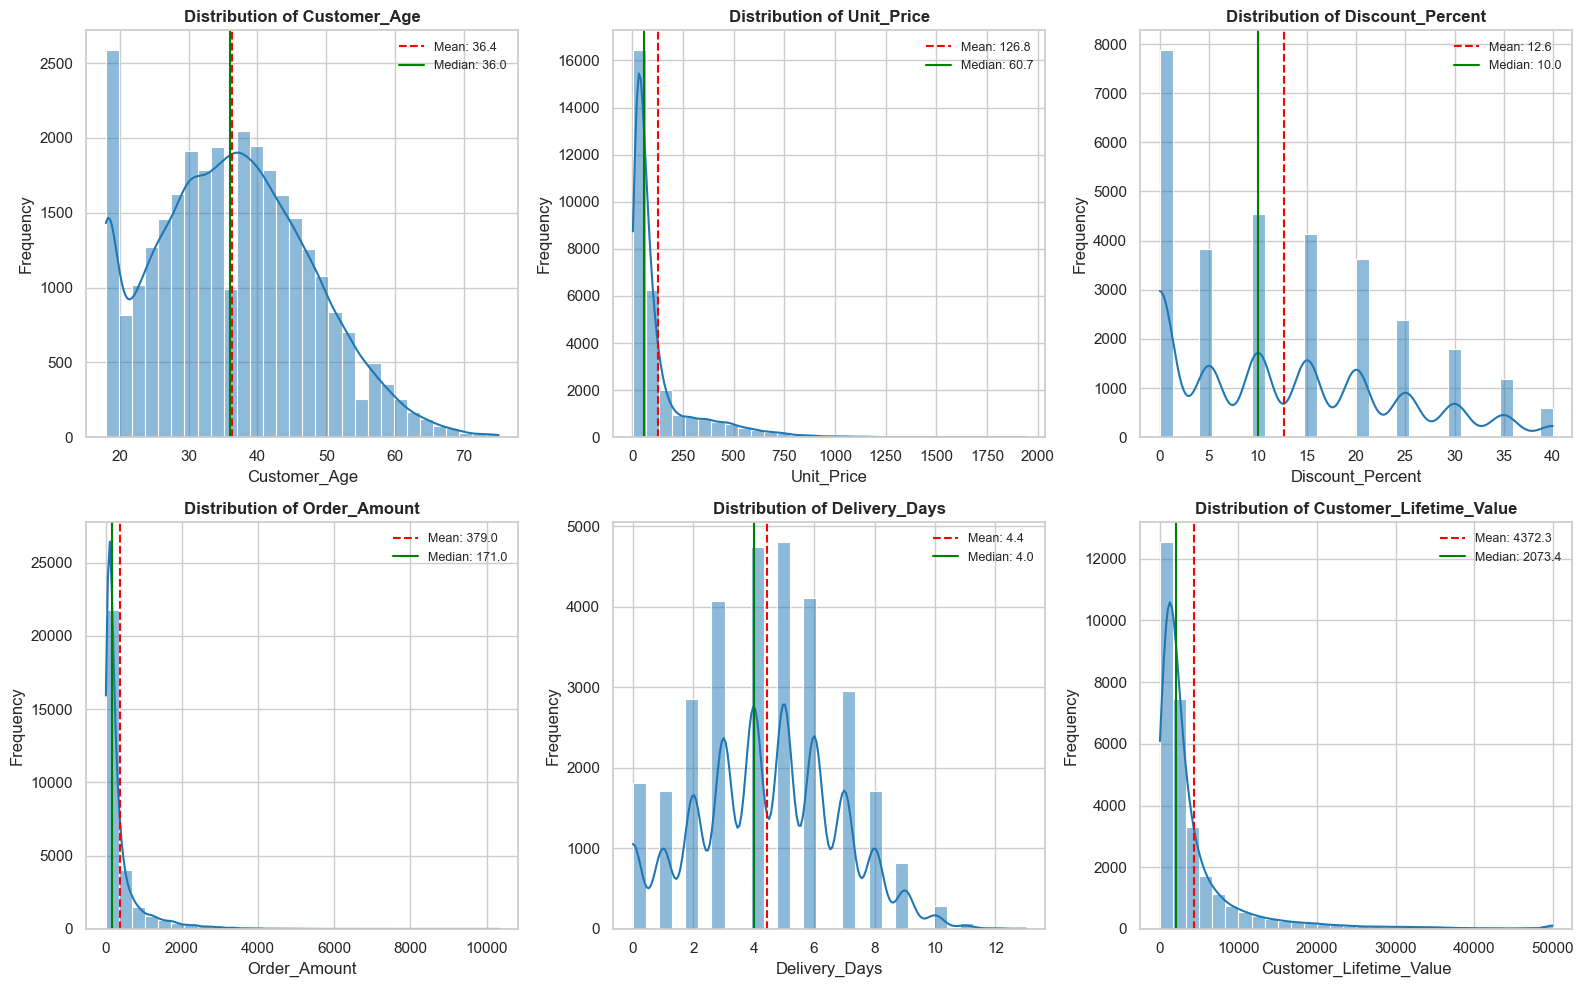

In [12]:
key_numeric = ['Customer_Age', 'Unit_Price', 'Discount_Percent', 'Order_Amount', 'Delivery_Days', 'Customer_Lifetime_Value']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(key_numeric):
    sns.histplot(df[col], kde=True, ax=axes[idx], color='#1f77b4', bins=30)
    axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')
    
    # Add mean and median vertical lines
    mean_val = df[col].mean()
    median_val = df[col].median()
    axes[idx].axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.1f}')
    axes[idx].axvline(median_val, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median_val:.1f}')
    axes[idx].legend(fontsize=9)

plt.tight_layout()
plt.show()


### 5.2 Outlier Detection via Boxplots and Interquartile Range (IQR) Thresholds
Identify potential outliers in financial and logistics attributes using boxplots and quantify the percentage of records outside 1.5 x IQR bounds.


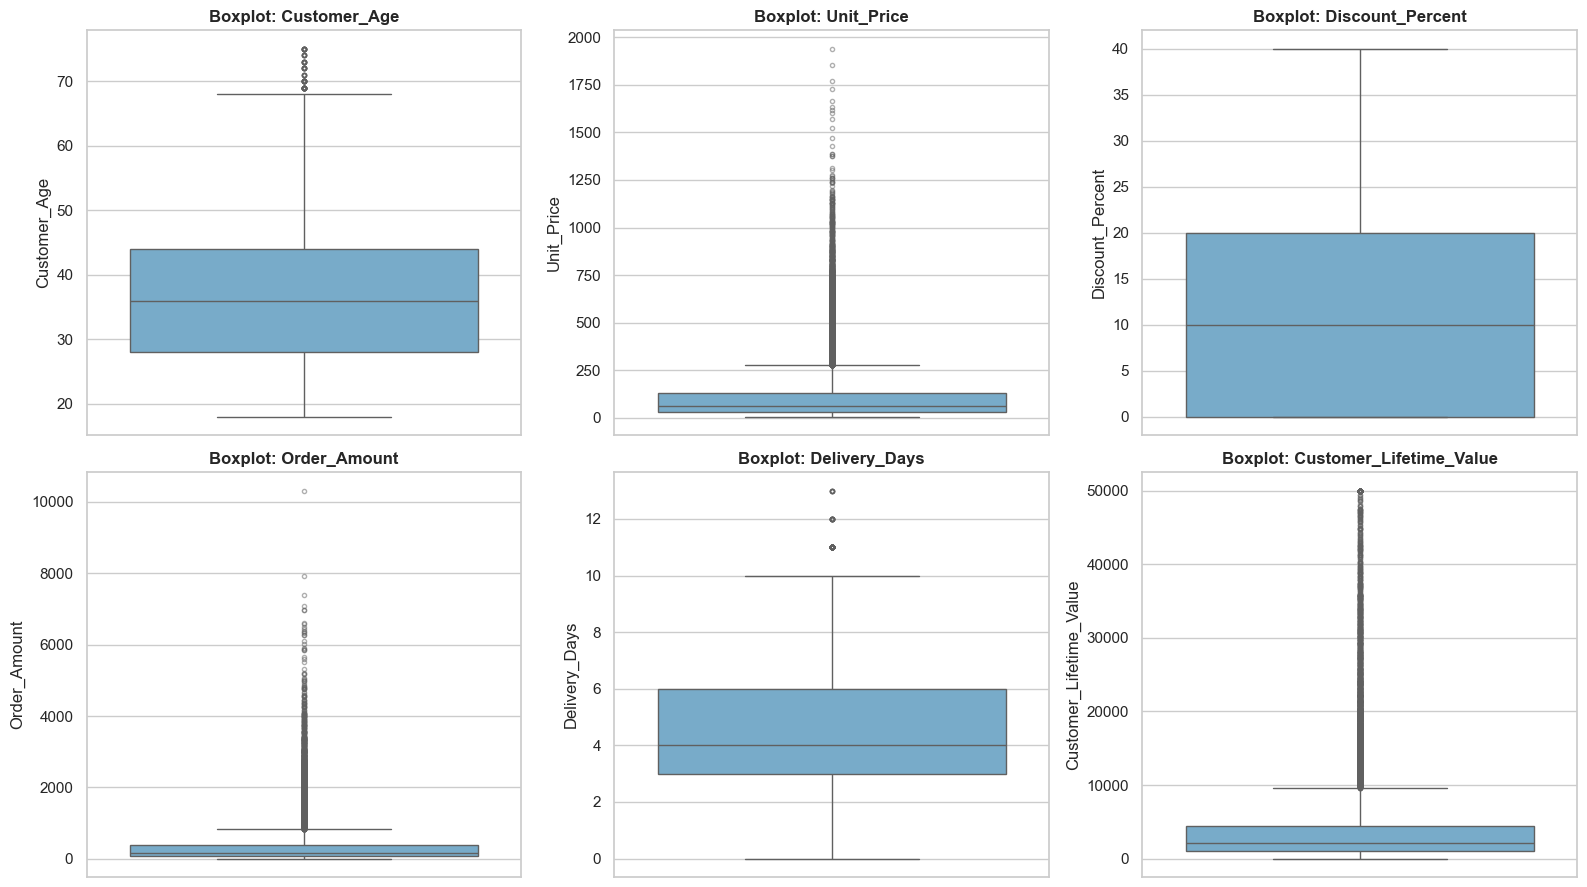

=== OUTLIER DETECTION SUMMARY (1.5 x IQR Rule) ===


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Customer_Age,4.000,68.000,98,0.330
1,Unit_Price,-118.160,276.610,4113,13.710
2,Discount_Percent,-30.000,50.000,0,0.000
3,Order_Amount,-374.920,846.050,3446,11.490
4,Delivery_Days,-1.500,10.500,94,0.310
5,Customer_Lifetime_Value,-4149.060,9660.810,3261,10.870


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

outlier_report = []

for idx, col in enumerate(key_numeric):
    sns.boxplot(y=df[col], ax=axes[idx], color='#6baed6', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.5})
    axes[idx].set_title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel(col)
    
    # IQR Outlier computation
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_count = len(outliers)
    outlier_pct = (outlier_count / len(df)) * 100
    
    outlier_report.append({
        'Feature': col,
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': outlier_count,
        'Outlier %': round(outlier_pct, 2)
    })

plt.tight_layout()
plt.show()

print("=== OUTLIER DETECTION SUMMARY (1.5 x IQR Rule) ===")
display(pd.DataFrame(outlier_report))


### 5.3 Categorical Feature Distributions: Product Categories, Segments, and Payment Methods
Examine the frequency distribution of primary categorical attributes to identify high-volume categories and potential class imbalances across predictors.


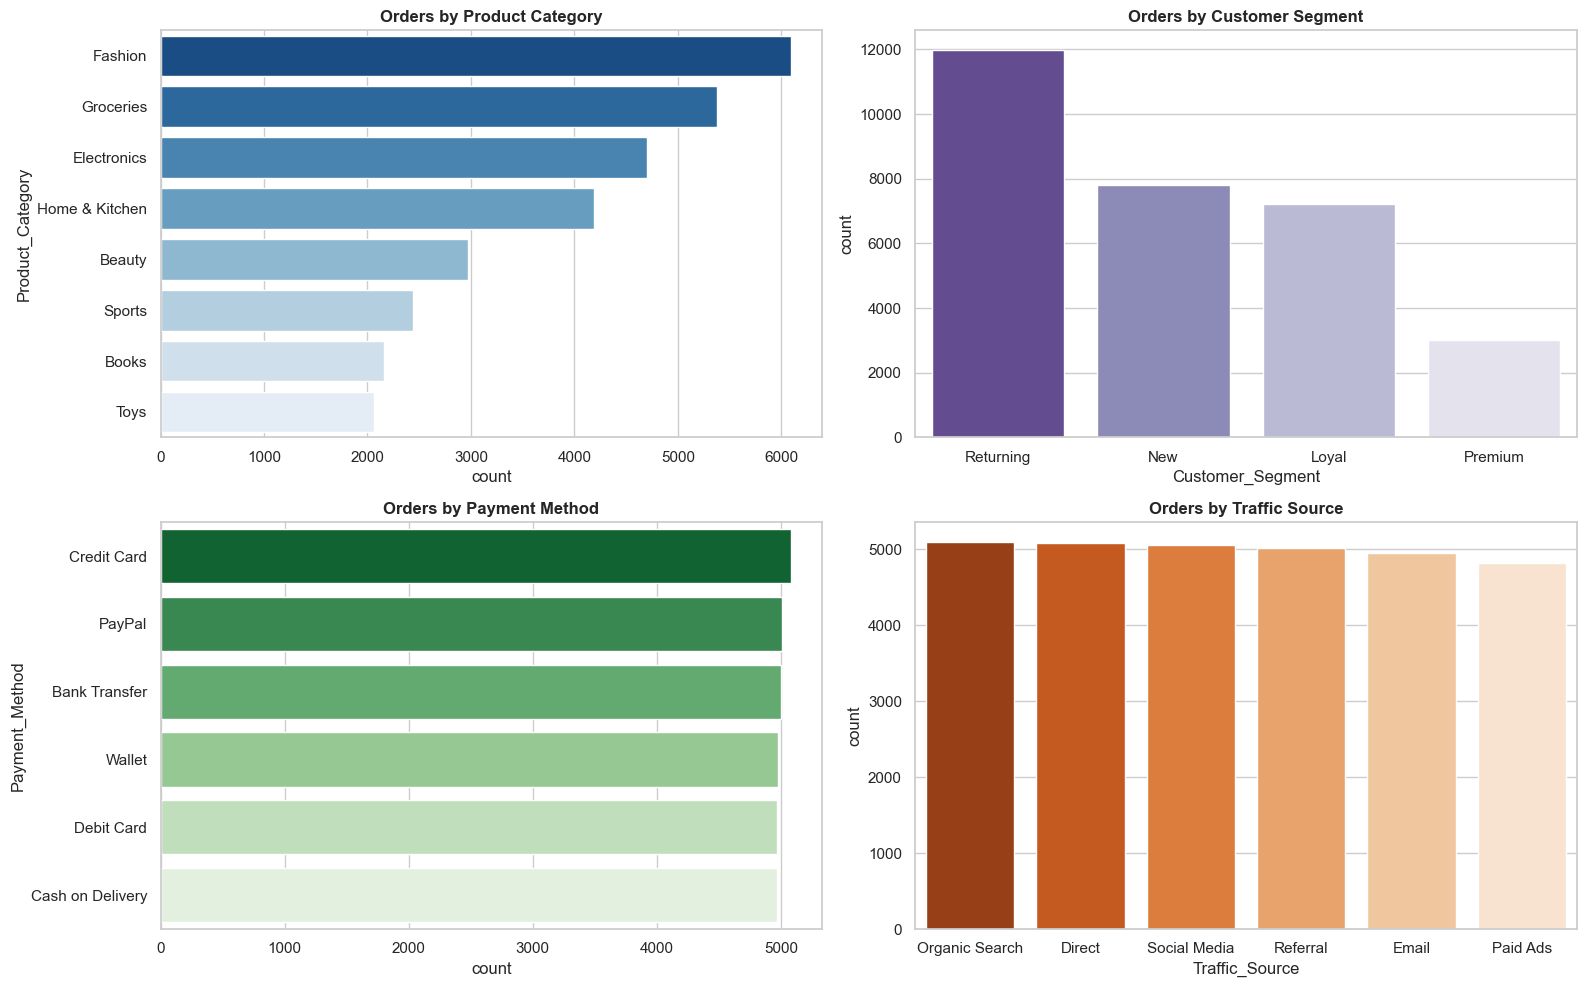

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Product Category
sns.countplot(data=df, y='Product_Category', order=df['Product_Category'].value_counts().index, 
              palette='Blues_r', ax=axes[0, 0])
axes[0, 0].set_title('Orders by Product Category', fontweight='bold')

# 2. Customer Segment
sns.countplot(data=df, x='Customer_Segment', order=df['Customer_Segment'].value_counts().index, 
              palette='Purples_r', ax=axes[0, 1])
axes[0, 1].set_title('Orders by Customer Segment', fontweight='bold')

# 3. Payment Method
sns.countplot(data=df, y='Payment_Method', order=df['Payment_Method'].value_counts().index, 
              palette='Greens_r', ax=axes[1, 0])
axes[1, 0].set_title('Orders by Payment Method', fontweight='bold')

# 4. Traffic Source
sns.countplot(data=df, x='Traffic_Source', order=df['Traffic_Source'].value_counts().index, 
              palette='Oranges_r', ax=axes[1, 1])
axes[1, 1].set_title('Orders by Traffic Source', fontweight='bold')

plt.tight_layout()
plt.show()


### 6.1 Return Rate by Product Category and Subcategory
Calculate the proportion of returned orders across each product category and identify product groups with elevated return propensities.


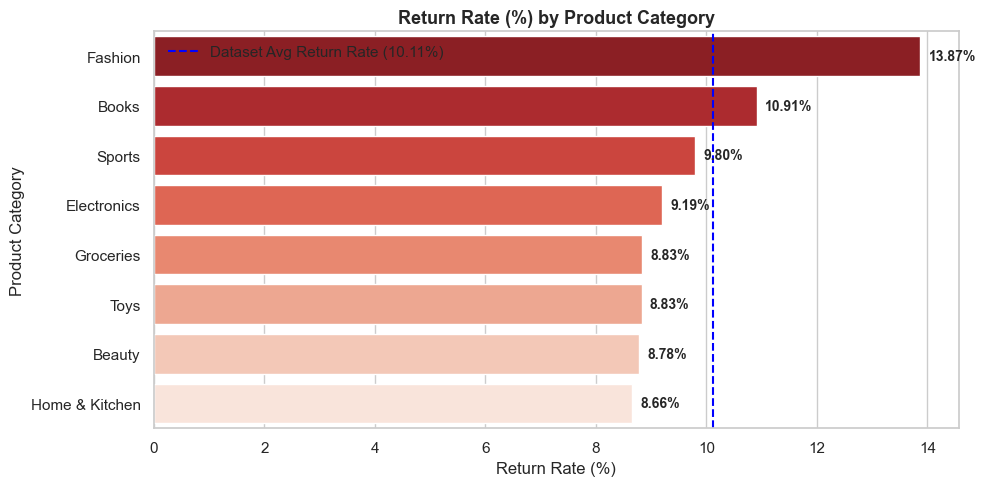

,Product_Category,Total_Orders,Returned_Orders,Return_Rate_Pct
3,Fashion,6092,845,13.871
1,Books,2163,236,10.911
6,Sports,2439,239,9.799
2,Electronics,4699,432,9.193
4,Groceries,5380,475,8.829
7,Toys,2062,182,8.826
0,Beauty,2971,261,8.785
5,Home & Kitchen,4194,363,8.655


In [15]:
# Create binary target indicator for easy rate calculations
df['Returned_Binary'] = (df['Returned'] == 'Yes').astype(int)

cat_return_rates = df.groupby('Product_Category').agg(
    Total_Orders=('Returned_Binary', 'count'),
    Returned_Orders=('Returned_Binary', 'sum'),
    Return_Rate_Pct=('Returned_Binary', lambda x: x.mean() * 100)
).reset_index().sort_values(by='Return_Rate_Pct', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cat_return_rates, x='Return_Rate_Pct', y='Product_Category', palette='Reds_r', ax=ax)
ax.axvline(df['Returned_Binary'].mean() * 100, color='blue', linestyle='--', linewidth=1.5, 
           label=f"Dataset Avg Return Rate ({df['Returned_Binary'].mean() * 100:.2f}%)")
ax.set_title('Return Rate (%) by Product Category', fontsize=13, fontweight='bold')
ax.set_xlabel('Return Rate (%)')
ax.set_ylabel('Product Category')
ax.legend()

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.2f}%", (width + 0.15, p.get_y() + p.get_height() / 2),
                va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

display(cat_return_rates)


### 6.2 Return Rate by Customer Demographics: Age Cohorts, Gender, and Segment
Analyze whether return behavior differs across customer demographics by binning customer ages and evaluating return rates across cohorts.


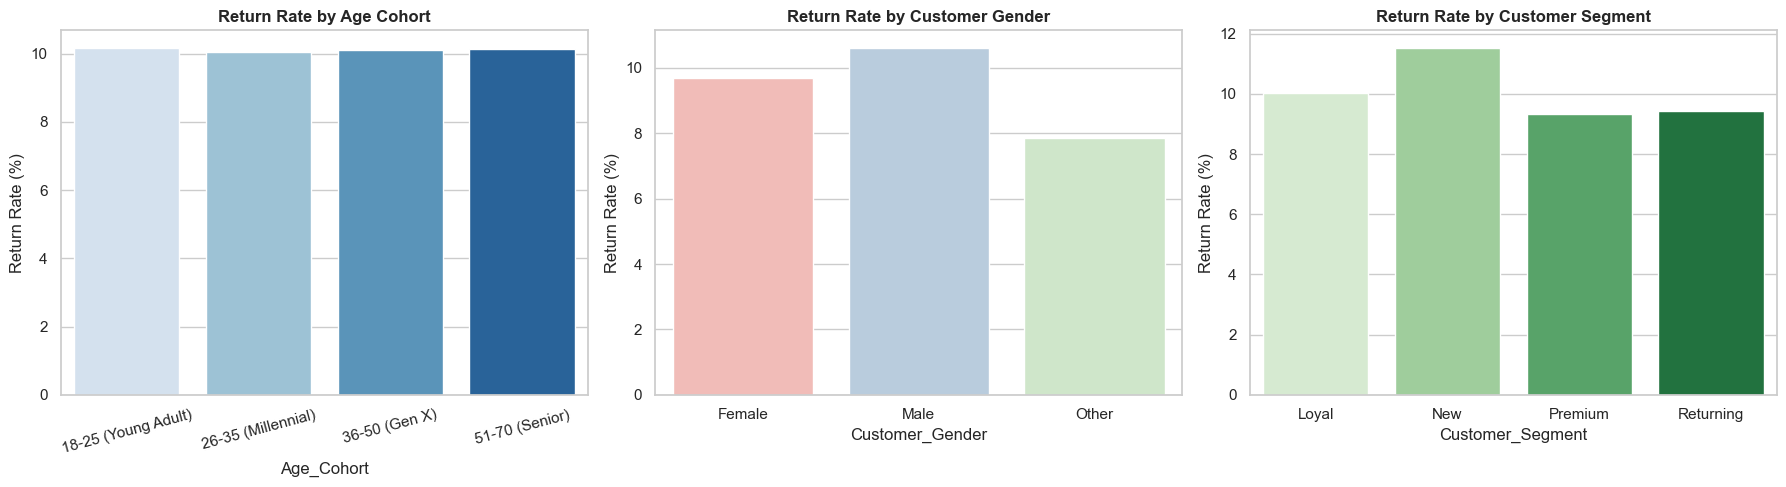

In [16]:
# Bin age into standard demographic brackets
df['Age_Cohort'] = pd.cut(df['Customer_Age'], 
                          bins=[17, 25, 35, 50, 70], 
                          labels=['18-25 (Young Adult)', '26-35 (Millennial)', '36-50 (Gen X)', '51-70 (Senior)'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Demographic 1: Age Cohort
age_rates = df.groupby('Age_Cohort')['Returned_Binary'].mean().reset_index()
age_rates['Return_Rate_Pct'] = age_rates['Returned_Binary'] * 100
sns.barplot(data=age_rates, x='Age_Cohort', y='Return_Rate_Pct', palette='Blues', ax=axes[0])
axes[0].set_title('Return Rate by Age Cohort', fontweight='bold')
axes[0].set_ylabel('Return Rate (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15)

# Demographic 2: Gender
gender_rates = df.groupby('Customer_Gender')['Returned_Binary'].mean().reset_index()
gender_rates['Return_Rate_Pct'] = gender_rates['Returned_Binary'] * 100
sns.barplot(data=gender_rates, x='Customer_Gender', y='Return_Rate_Pct', palette='Pastel1', ax=axes[1])
axes[1].set_title('Return Rate by Customer Gender', fontweight='bold')
axes[1].set_ylabel('Return Rate (%)')

# Demographic 3: Customer Segment
seg_rates = df.groupby('Customer_Segment')['Returned_Binary'].mean().reset_index()
seg_rates['Return_Rate_Pct'] = seg_rates['Returned_Binary'] * 100
sns.barplot(data=seg_rates, x='Customer_Segment', y='Return_Rate_Pct', palette='Greens', ax=axes[2])
axes[2].set_title('Return Rate by Customer Segment', fontweight='bold')
axes[2].set_ylabel('Return Rate (%)')

plt.tight_layout()
plt.show()


### 6.3 Return Propensity vs. Order & Logistics Attributes (Discounts, Order Amount, Delivery Days)
Evaluate the relationship between return propensity and key operational drivers: delivery duration, discounts applied, and basket value.


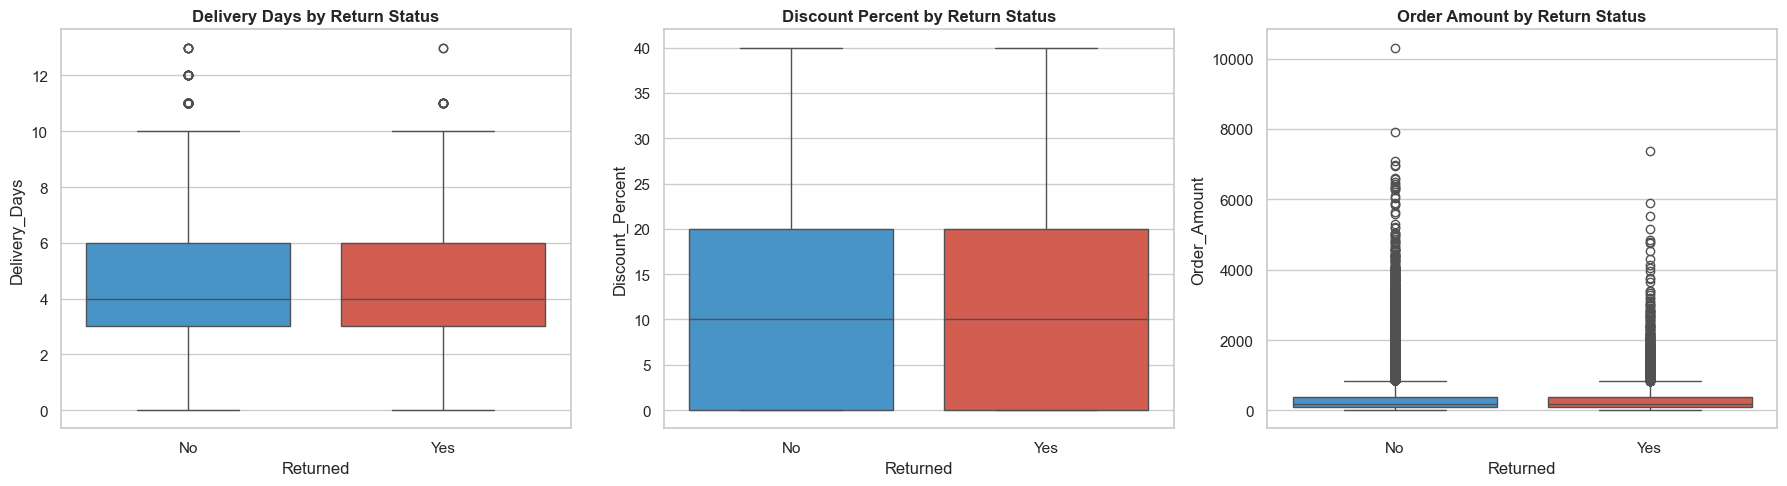

=== COMPARISON OF MEANS BY RETURN STATUS ===


Returned,No,Yes,Difference (Yes - No)
Delivery_Days,4.434,4.460,0.026
Discount_Percent,12.642,12.415,-0.226
Order_Amount,380.054,369.641,-10.413
Review_Rating,4.157,3.076,-1.081


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Delivery Days vs Returned
sns.boxplot(data=df, x='Returned', y='Delivery_Days', palette=['#3498db', '#e74c3c'], ax=axes[0])
axes[0].set_title('Delivery Days by Return Status', fontweight='bold')

# 2. Discount Percent vs Returned
sns.boxplot(data=df, x='Returned', y='Discount_Percent', palette=['#3498db', '#e74c3c'], ax=axes[1])
axes[1].set_title('Discount Percent by Return Status', fontweight='bold')

# 3. Order Amount vs Returned
sns.boxplot(data=df, x='Returned', y='Order_Amount', palette=['#3498db', '#e74c3c'], ax=axes[2])
axes[2].set_title('Order Amount by Return Status', fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical comparison of means
comparison_table = df.groupby('Returned')[['Delivery_Days', 'Discount_Percent', 'Order_Amount', 'Review_Rating']].mean().T
comparison_table['Difference (Yes - No)'] = comparison_table['Yes'] - comparison_table['No']
print("=== COMPARISON OF MEANS BY RETURN STATUS ===")
display(comparison_table.round(3))


### 6.4 Customer Review Ratings vs. Return Propensity
Investigate whether post-purchase customer satisfaction / review rating correlates with the likelihood of returning an item.


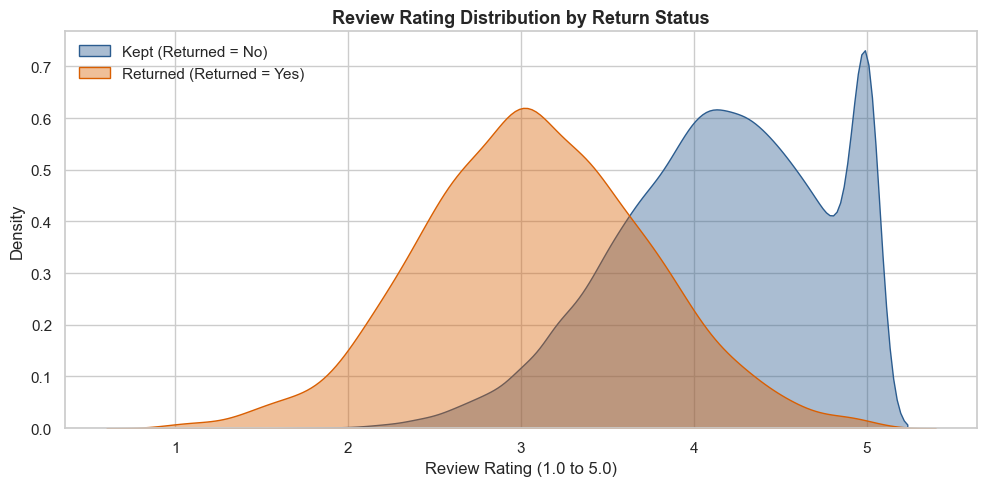

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.kdeplot(data=df[df['Returned'] == 'No']['Review_Rating'], label='Kept (Returned = No)', 
           color='#2b5c8f', fill=True, alpha=0.4, ax=ax)
sns.kdeplot(data=df[df['Returned'] == 'Yes']['Review_Rating'], label='Returned (Returned = Yes)', 
           color='#d95f02', fill=True, alpha=0.4, ax=ax)

ax.set_title('Review Rating Distribution by Return Status', fontsize=13, fontweight='bold')
ax.set_xlabel('Review Rating (1.0 to 5.0)')
ax.set_ylabel('Density')
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


### 7.1 Multicollinearity & Correlation Analysis Among Numerical Attributes
Compute the Pearson correlation matrix across numerical features to identify strong inter-correlations or redundant variables before training.


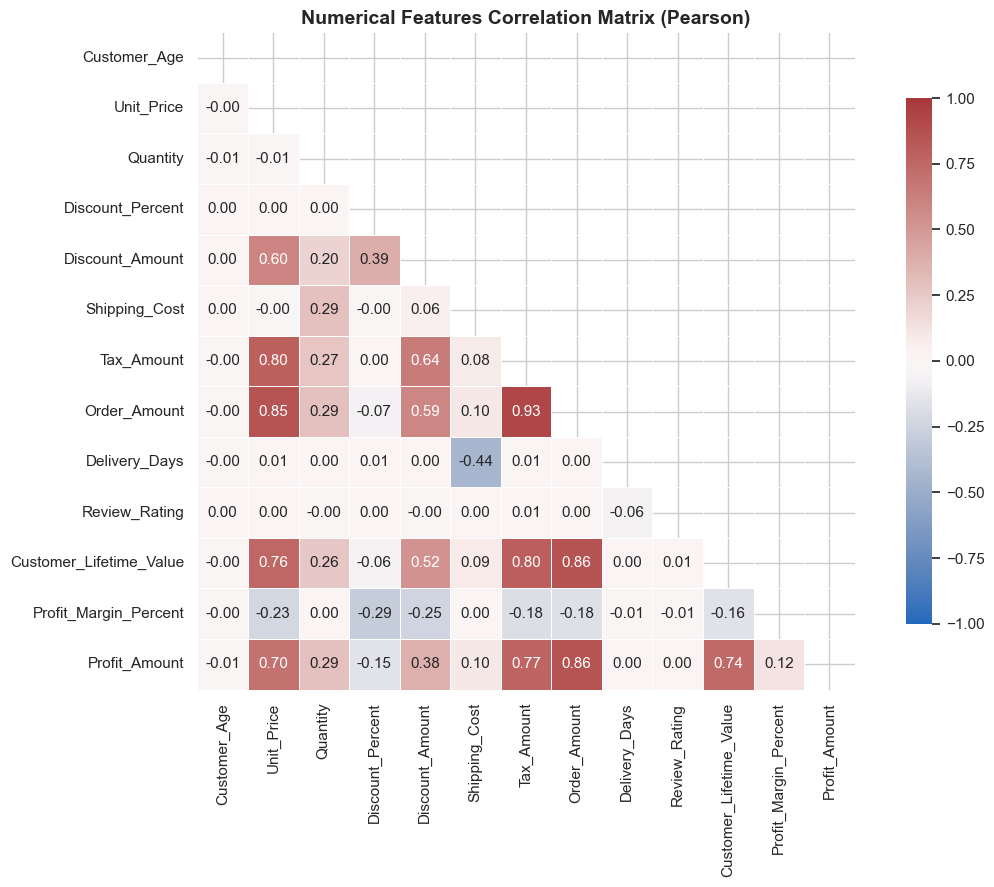

In [19]:
corr_features = ['Customer_Age', 'Unit_Price', 'Quantity', 'Discount_Percent', 
                 'Discount_Amount', 'Shipping_Cost', 'Tax_Amount', 'Order_Amount', 
                 'Delivery_Days', 'Review_Rating', 'Customer_Lifetime_Value', 
                 'Profit_Margin_Percent', 'Profit_Amount']

corr_matrix = df[corr_features].corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='vlag', 
            vmin=-1, vmax=1, center=0, square=True, linewidths=.5, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Numerical Features Correlation Matrix (Pearson)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### 7.2 Point-Biserial Correlation of Predictive Features with the Target Variable
Calculate and rank the correlation of all numeric features with `Returned_Binary` to identify the most potent linear predictors of customer return propensity.


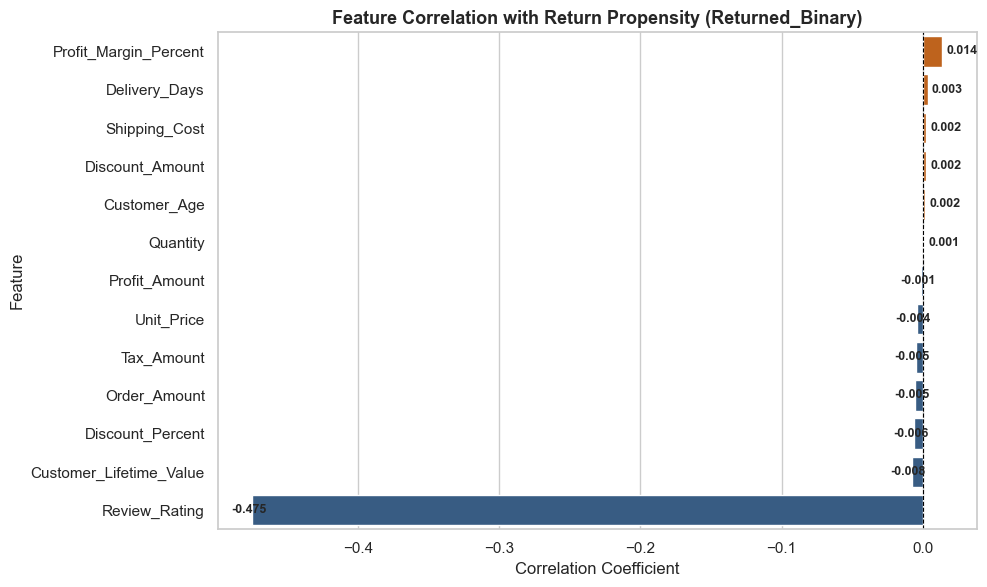

,Feature,Correlation_with_Returned
11,Profit_Margin_Percent,0.014
8,Delivery_Days,0.003
5,Shipping_Cost,0.003
4,Discount_Amount,0.002
0,Customer_Age,0.002
2,Quantity,0.001
12,Profit_Amount,-0.001
1,Unit_Price,-0.004
6,Tax_Amount,-0.005
7,Order_Amount,-0.005


In [20]:
target_correlations = df[corr_features].apply(lambda col: df['Returned_Binary'].corr(col))
target_corr_df = pd.DataFrame({
    'Feature': target_correlations.index,
    'Correlation_with_Returned': target_correlations.values
}).sort_values(by='Correlation_with_Returned', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = ['#d95f02' if x > 0 else '#2b5c8f' for x in target_corr_df['Correlation_with_Returned']]
sns.barplot(data=target_corr_df, x='Correlation_with_Returned', y='Feature', palette=bar_colors, ax=ax)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Feature Correlation with Return Propensity (Returned_Binary)', fontsize=13, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')

for p in ax.patches:
    width = p.get_width()
    offset = 0.003 if width >= 0 else -0.015
    ax.annotate(f"{width:.3f}", (width + offset, p.get_y() + p.get_height() / 2),
                va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

display(target_corr_df.round(4))


### 8.1 Data Leakage Audit & Target Leakage Prevention
Audit dataset columns to identify variables that would NOT be available at the time of order placement or inferring return propensity (e.g., `Order_Status`, post-order reviews, or future accounting metrics).


In [21]:
print("=== AUDITING DATA LEAKAGE: Order_Status vs. Returned ===")
status_return_crosstab = pd.crosstab(df['Order_Status'], df['Returned'], margins=True)
display(status_return_crosstab)

print("\n=== POTENTIAL TARGET LEAKAGE COLUMNS IDENTIFIED ===")
leakage_candidates = [
    ('Order_Status', 'Directly mirrors the return event; 100% target leakage if used as a predictor.'),
    ('Review_Rating', 'Written days/weeks AFTER order receipt; unavailable at time of order creation (useful only for post-delivery return monitoring).'),
    ('Profit_Amount', 'Derived post-sale accounting metric.'),
    ('High_Value_Order', 'Alternative target definition.')
]

leakage_df = pd.DataFrame(leakage_candidates, columns=['Column_Name', 'Leakage_Risk_Rationale'])
display(leakage_df)


=== AUDITING DATA LEAKAGE: Order_Status vs. Returned ===


Returned,No,Yes,All
Order_Status,,,
Cancelled,1771,0,1771
Delivered,19497,0,19497
Processing,2230,0,2230
Returned,0,3033,3033
Shipped,3469,0,3469
All,26967,3033,30000



=== POTENTIAL TARGET LEAKAGE COLUMNS IDENTIFIED ===


,Column_Name,Leakage_Risk_Rationale
0,Order_Status,Directly mirrors the return event; 100% target...
1,Review_Rating,Written days/weeks AFTER order receipt; unavai...
2,Profit_Amount,Derived post-sale accounting metric.
3,High_Value_Order,Alternative target definition.


### 8.2 Machine Learning Suitability Scorecard and Final Verdict
Synthesize all statistical, quality, and distributional findings into a comprehensive Machine Learning Suitability Scorecard to evaluate whether this dataset is ready for model development.


In [22]:
scorecard = [
    {
        "Evaluation Criterion": "1. Sample Size & Statistical Power",
        "Assessment": "Excellent (30,000 records)",
        "Details": "Provides ample statistical power for training complex non-linear models (e.g., XGBoost, LightGBM, Random Forest) with stratified k-fold splits."
    },
    {
        "Evaluation Criterion": "2. Data Cleanliness & Missingness",
        "Assessment": "Pristine (0% Missing Values)",
        "Details": "No missing or NaN records across all 41 columns. Imputation pipelines are not strictly required for baseline development."
    },
    {
        "Evaluation Criterion": "3. Target Class Imbalance",
        "Assessment": "Moderate Imbalance (10.11% Returned, ~9:1 ratio)",
        "Details": "Realistic for e-commerce return rates. Requires threshold tuning, class weighting (scale_pos_weight), and evaluation via PR-AUC / ROC-AUC instead of standard Accuracy."
    },
    {
        "Evaluation Criterion": "4. Feature Diversity & Signal",
        "Assessment": "High Dimensionality & Rich Feature Types",
        "Details": "Includes customer demographics, basket properties, pricing/discounts, logistics (Delivery_Days, Warehouse), and temporal attributes."
    },
    {
        "Evaluation Criterion": "5. Data Leakage Precautions",
        "Assessment": "Manageable with Strict Feature Selection",
        "Details": "Crucial to exclude 'Order_Status' (which contains 'Returned' as a status) and post-event attributes from the feature matrix X."
    },
    {
        "Evaluation Criterion": "6. FINAL VERDICT FOR ML MODELING",
        "Assessment": "SUITABLE & RECOMMENDED",
        "Details": "This dataset is well-structured and highly viable for building a supervised classification pipeline to predict customer return propensity."
    }
]

scorecard_df = pd.DataFrame(scorecard)
print("=========================================================================================")
print("             MACHINE LEARNING READINESS SCORECARD & SUITABILITY VERDICT                  ")
print("=========================================================================================")
display(scorecard_df.style.set_properties(**{'text-align': 'left'}))


             MACHINE LEARNING READINESS SCORECARD & SUITABILITY VERDICT                  


,Evaluation Criterion,Assessment,Details
0,1. Sample Size & Statistical Power,"Excellent (30,000 records)","Provides ample statistical power for training complex non-linear models (e.g., XGBoost, LightGBM, Random Forest) with stratified k-fold splits."
1,2. Data Cleanliness & Missingness,Pristine (0% Missing Values),No missing or NaN records across all 41 columns. Imputation pipelines are not strictly required for baseline development.
2,3. Target Class Imbalance,"Moderate Imbalance (10.11% Returned, ~9:1 ratio)","Realistic for e-commerce return rates. Requires threshold tuning, class weighting (scale_pos_weight), and evaluation via PR-AUC / ROC-AUC instead of standard Accuracy."
3,4. Feature Diversity & Signal,High Dimensionality & Rich Feature Types,"Includes customer demographics, basket properties, pricing/discounts, logistics (Delivery_Days, Warehouse), and temporal attributes."
4,5. Data Leakage Precautions,Manageable with Strict Feature Selection,Crucial to exclude 'Order_Status' (which contains 'Returned' as a status) and post-event attributes from the feature matrix X.
5,6. FINAL VERDICT FOR ML MODELING,SUITABLE & RECOMMENDED,This dataset is well-structured and highly viable for building a supervised classification pipeline to predict customer return propensity.
